# CISC7204 Pair14: College Tuition and Graduate Earnings

**Research question:** Is annual undergraduate tuition associated with the median earnings of students who are working and not enrolled 10 years after entering U.S. four-year colleges, and does this relationship differ between public and private institutions?

**Implementation sample only:** This Notebook demonstrates the planned data preparation, calculations, and visualizations. It is not the final results discussion. Each chart is introduced by its type, what it displays, and why it is used; the Notebook does not interpret the results or draw conclusions.


## Public tuition comparison baseline

Public in-state tuition is the main public benchmark because it is the standard resident rate and provides a consistent base comparison with private-college tuition. Out-of-state tuition appears only in the first tuition-distribution box plot. All later statistics and charts compare Private with Public In-State.


## Data source and project files

The source is the College Scorecard institution-level file `Most-Recent-Cohorts-Institution.csv`. Keep this file in the same folder as the Notebook before running it. The cleaning step saves the analysis file as `cleaned_data.csv`.


## Variables and comparison groups

The analysis uses institution name and identifier, predominant degree, control code, in-state tuition, out-of-state tuition, 10-year median earnings, and earnings observation count. The tuition box plot displays three categories: Private, Public In-State, and Public Out-of-State. The later statistics and visualizations compare only Private and Public In-State. The supplied private tuition values match across the two tuition columns, so each private institution is included once.


## Import the analysis libraries

This cell imports pandas and NumPy for data preparation and summary calculations, and Matplotlib and Seaborn for the chart types used in the project.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Load and inspect the selected source fields

This cell reads only the fields needed for the research question, then reports the table dimensions and displays a sample to confirm the source columns loaded.


In [2]:
raw_file = 'Most-Recent-Cohorts-Institution.csv'

useful_columns = [
    'UNITID', 'INSTNM', 'PREDDEG', 'CONTROL',
    'TUITIONFEE_IN', 'TUITIONFEE_OUT', 'MD_EARN_WNE_P10', 'COUNT_WNE_P10'
]

raw_df = pd.read_csv(raw_file, usecols=useful_columns, low_memory=False)
print('Rows and columns loaded:', raw_df.shape)
raw_df.head()


Rows and columns loaded: (6278, 8)


,UNITID,INSTNM,PREDDEG,CONTROL,TUITIONFEE_IN,TUITIONFEE_OUT,COUNT_WNE_P10,MD_EARN_WNE_P10
0,100654,Alabama A & M University,3,1,10558.0,19318.0,1671,41266
1,100663,University of Alabama at Birmingham,3,1,9812.0,23684.0,4036,59631
2,100690,Amridge University,3,2,NaN,NaN,271,40519
3,100706,University of Alabama in Huntsville,3,1,12458.0,27148.0,1788,72098
4,100724,Alabama State University,3,1,11248.0,19576.0,2428,40585


## Rename fields and check missing values

This cell gives the source fields short working names and counts missing values in tuition, earnings, and earnings-count variables before filtering.


In [3]:
college_df = raw_df.rename(columns={
    'UNITID': 'unit_id',
    'INSTNM': 'institution_name',
    'PREDDEG': 'predominant_degree',
    'CONTROL': 'control_code',
    'TUITIONFEE_IN': 'tuition_in',
    'TUITIONFEE_OUT': 'tuition_out',
    'MD_EARN_WNE_P10': 'earnings_10yr',
    'COUNT_WNE_P10': 'earnings_count'
})

missing_before = college_df[['tuition_in', 'tuition_out', 'earnings_10yr', 'earnings_count']].isnull().sum()
missing_before


tuition_in        2632
tuition_out       2632
earnings_10yr      362
earnings_count     362
dtype: int64

## Select four-year colleges and convert suppressed values

This cell keeps predominantly bachelor's-degree institutions (`PREDDEG` 3), converts the `PS` suppression code to a missing value, and makes the earnings fields numeric so they can be cleaned and summarized.


In [4]:
four_year_df = college_df.query('predominant_degree == 3').copy()

four_year_df['earnings_10yr'] = four_year_df['earnings_10yr'].replace('PS', np.nan).astype(float)
four_year_df['earnings_count'] = four_year_df['earnings_count'].replace('PS', np.nan).astype(float)

print('Rows for predominantly bachelor degree institutions:', len(four_year_df))
print('Missing values after converting suppression codes:')
four_year_df[['tuition_in', 'tuition_out', 'earnings_10yr', 'earnings_count']].isnull().sum()


Rows for predominantly bachelor degree institutions: 1947
Missing values after converting suppression codes:


tuition_in         91
tuition_out        91
earnings_10yr     142
earnings_count    142
dtype: int64

## Remove unusable records and label institution types

This cell removes records with missing or non-positive tuition, earnings, or earnings-count values. It maps control codes 1 to Public and 2 or 3 to Private, then drops the classification fields that are no longer needed.


In [5]:
cleaned_df = four_year_df.query(
    'tuition_in == tuition_in and tuition_out == tuition_out and '
    'earnings_10yr == earnings_10yr and earnings_count == earnings_count and '
    'tuition_in > 0 and tuition_out > 0 and earnings_10yr > 0 and earnings_count > 0'
).copy()

cleaned_df['institution_type'] = cleaned_df['control_code'].replace({
    1: 'Public',
    2: 'Private',
    3: 'Private'
})
cleaned_df = cleaned_df.query("institution_type == 'Public' or institution_type == 'Private'").copy()
cleaned_df = cleaned_df.drop(columns=['predominant_degree', 'control_code'])

print('Rows after missing and invalid-value handling:', len(cleaned_df))
cleaned_df.groupby('institution_type')['unit_id'].count().reset_index()


Rows after missing and invalid-value handling: 1731


,institution_type,unit_id
0,Private,1165
1,Public,566


## Save the cleaned analysis file

This cell keeps the fields required by the charts, checks that private tuition is the same in both source columns, and saves the cleaned records as `cleaned_data.csv`. The check supports using one private tuition value per college in the three-group comparison.


In [6]:
final_columns = [
    'unit_id', 'institution_name', 'tuition_in',
    'tuition_out', 'earnings_10yr', 'earnings_count', 'institution_type'
]
cleaned_df = cleaned_df[final_columns]

private_check = cleaned_df.query("institution_type == 'Private'")
private_tuition_matches = private_check['tuition_in'].equals(private_check['tuition_out'])
print('Private in-state and out-of-state tuition values match:', private_tuition_matches)

cleaned_df.to_csv('cleaned_data.csv', index=False)
print('Cleaned data file saved as cleaned_data.csv')
cleaned_df.head()


Private in-state and out-of-state tuition values match: True
Cleaned data file saved as cleaned_data.csv


,unit_id,institution_name,tuition_in,tuition_out,earnings_10yr,earnings_count,institution_type
0,100654,Alabama A & M University,10558.0,19318.0,41266.0,1671.0,Public
1,100663,University of Alabama at Birmingham,9812.0,23684.0,59631.0,4036.0,Public
3,100706,University of Alabama in Huntsville,12458.0,27148.0,72098.0,1788.0,Public
4,100724,Alabama State University,11248.0,19576.0,40585.0,2428.0,Public
5,100751,The University of Alabama,12484.0,35342.0,66081.0,7344.0,Public


## Build the tuition and primary comparison groups

This cell creates three tuition groups for the first box plot: Private, Public In-State, and Public Out-of-State. It also creates the two-group analysis table used in all later statistics and visualizations: Private and Public In-State. Private colleges use one tuition value because the two supplied columns match.


In [7]:
private_df = cleaned_df.query("institution_type == 'Private'").copy()
private_df['category'] = 'Private'
private_df['tuition'] = private_df['tuition_in']

public_df = cleaned_df.query("institution_type == 'Public'").copy()
public_in_df = public_df.copy()
public_in_df['category'] = 'Public In-State'
public_in_df['tuition'] = public_in_df['tuition_in']

public_out_df = public_df.copy()
public_out_df['category'] = 'Public Out-of-State'
public_out_df['tuition'] = public_out_df['tuition_out']

tuition_df = pd.concat([private_df, public_in_df, public_out_df], ignore_index=True)
analysis_df = pd.concat([private_df, public_in_df], ignore_index=True)
category_order = ['Private', 'Public In-State']
tuition_order = ['Private', 'Public In-State', 'Public Out-of-State']
chart_colors = {
    'Private': 'seagreen',
    'Public In-State': sns.color_palette()[0],
    'Public Out-of-State': 'orange'
}

analysis_df[['category', 'tuition', 'earnings_10yr']].head()


,category,tuition,earnings_10yr
0,Private,18145.0,39314.0
1,Private,26590.0,48627.0
2,Private,29570.0,54423.0
3,Private,12710.0,47059.0
4,Private,13264.0,38127.0


## Calculate the comparison statistics

This cell calculates mean, median, maximum, minimum, and sample variance for the institution-level earnings measure in each group. It also calculates mean tuition and the ratio of mean earnings divided by mean tuition, expressed as a multiple. The table provides the values used in the radar charts.


In [8]:
earnings_stats = analysis_df.groupby('category')['earnings_10yr'].agg(
    ['mean', 'median', 'max', 'min', 'var']
)
mean_tuition = analysis_df.groupby('category')['tuition'].mean()

summary_table = earnings_stats.copy()
summary_table['mean_tuition'] = mean_tuition
summary_table['earnings_tuition_ratio'] = (
    summary_table['mean'] / summary_table['mean_tuition']
)
summary_table = summary_table.reindex(category_order)
summary_table = summary_table.rename(columns={
    'mean': 'mean_earnings',
    'median': 'median_earnings',
    'max': 'maximum_earnings',
    'min': 'minimum_earnings',
    'var': 'earnings_variance'
})
summary_table.round(2)


,mean_earnings,median_earnings,maximum_earnings,minimum_earnings,earnings_variance,mean_tuition,earnings_tuition_ratio
category,,,,,,,
Private,60801.12,58029.0,166642.0,19545.0,3.820321e+08,36106.62,1.68
Public In-State,60545.88,59271.5,114210.0,24622.0,1.660807e+08,11012.49,5.50


## Tuition distribution box plot

A box plot displays the median, quartiles, spread, and outliers of annual tuition. Its three boxes compare Private, Public In-State, and Public Out-of-State tuition; this is the only visualization that includes out-of-state tuition.


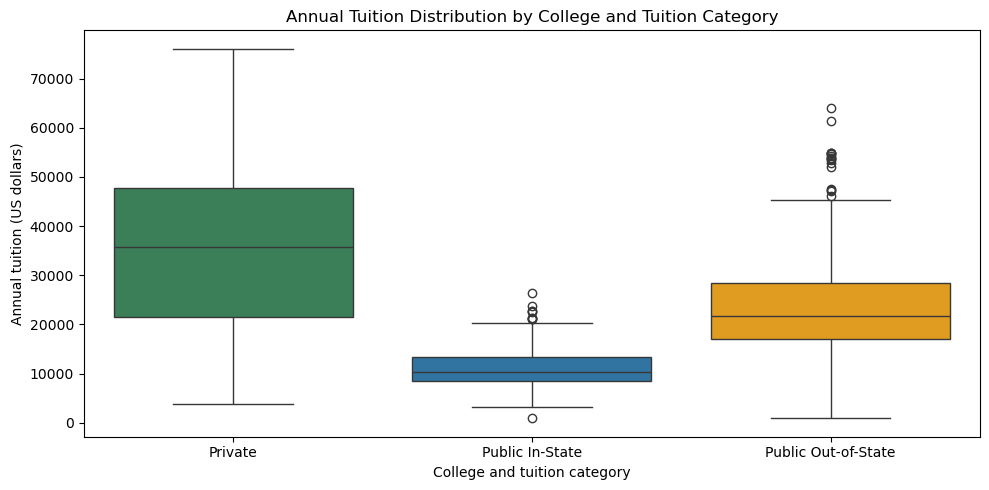

In [9]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=tuition_df,
    x='category',
    y='tuition',
    order=tuition_order,
    hue='category',
    hue_order=tuition_order,
    palette=chart_colors,
    legend=False
)
plt.title('Annual Tuition Distribution by College and Tuition Category')
plt.xlabel('College and tuition category')
plt.ylabel('Annual tuition (US dollars)')
plt.tight_layout()
plt.show()


## Tuition and earnings scatter plots

These side-by-side Seaborn regression scatter plots compare the Private group and the Public In-State group. Each point represents one college; the x-axis shows the group's tuition measure and the y-axis shows its median earnings 10 years after entry. Using the same earnings scale makes the two primary categories easy to compare.


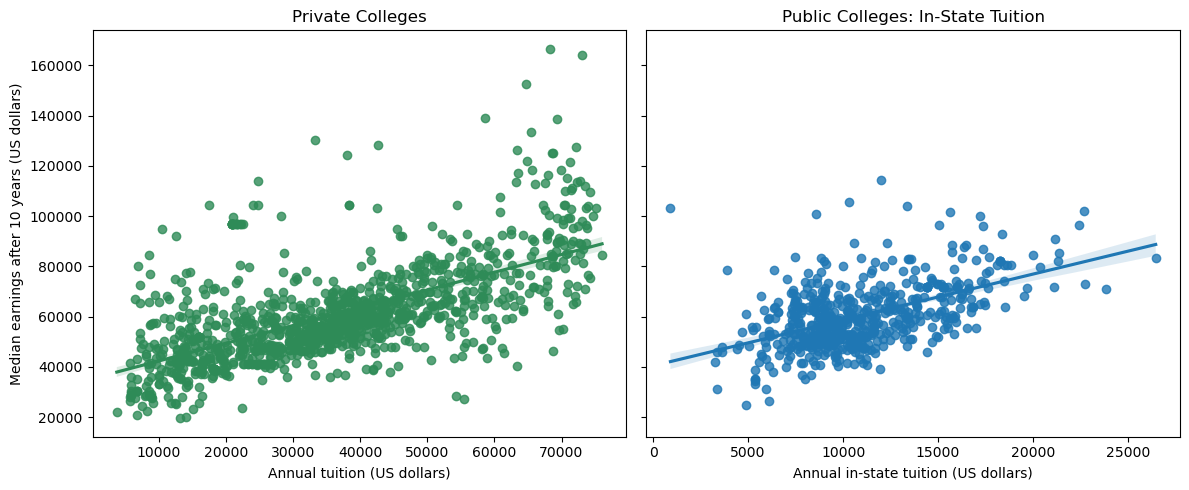

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

sns.regplot(
    data=private_df,
    x='tuition_in',
    y='earnings_10yr',
    color=chart_colors['Private'],
    ax=axes[0]
)
axes[0].set_title('Private Colleges')
axes[0].set_xlabel('Annual tuition (US dollars)')
axes[0].set_ylabel('Median earnings after 10 years (US dollars)')

sns.regplot(
    data=public_in_df,
    x='tuition_in',
    y='earnings_10yr',
    color=chart_colors['Public In-State'],
    ax=axes[1]
)
axes[1].set_title('Public Colleges: In-State Tuition')
axes[1].set_xlabel('Annual in-state tuition (US dollars)')
axes[1].set_ylabel('')

fig.tight_layout()
plt.show()


## Two-panel radar charts for group statistics

The radar charts show one profile each for Private and Public In-State across seven measures: mean, median, maximum, minimum, and sample variance of earnings, mean tuition, and the mean-earnings-to-mean-tuition ratio. Each axis label includes its original group value. The values are normalized internally to let measures with different units share the chart, while the ratio tick labels are hidden.


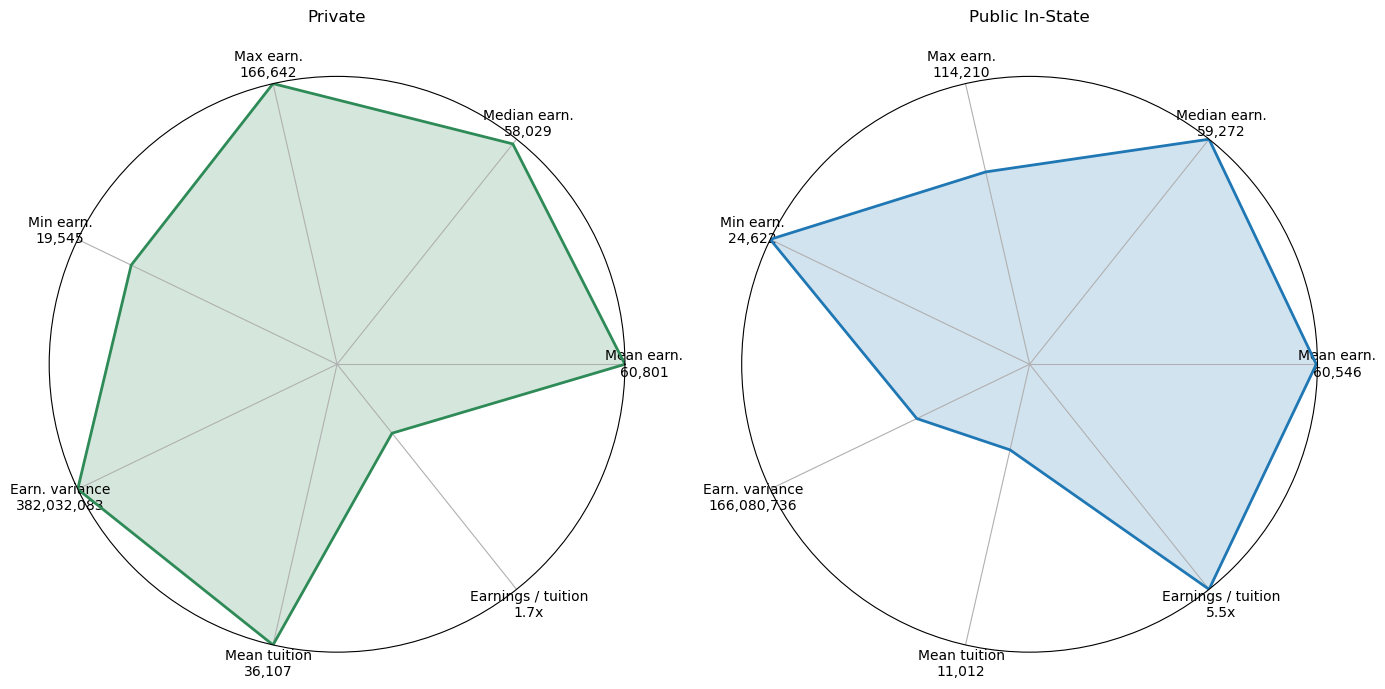

In [11]:
metric_labels = [
    'Mean earn.', 'Median earn.', 'Max earn.',
    'Min earn.', 'Earn. variance', 'Mean tuition', 'Earnings / tuition'
]
radar_raw = summary_table.copy()
radar_values = radar_raw.copy()
radar_values.columns = metric_labels
radar_values = radar_values.div(radar_values.max(axis=0), axis=1)

def format_radar_value(label, value):
    if label == 'Earnings / tuition':
        return f'{value:.1f}x'
    return f'{value:,.0f}'

angles = np.linspace(0, 2 * np.pi, len(metric_labels), endpoint=False)
closed_angles = np.concatenate([angles, [angles[0]]])
fig, axes = plt.subplots(1, 2, figsize=(14, 7), subplot_kw={'projection': 'polar'})

for ax, category in zip(axes, category_order):
    values = radar_values.loc[category].values
    raw_values = radar_raw.loc[category].values
    closed_values = np.concatenate([values, [values[0]]])
    axis_labels = [
        f'{label}\n{format_radar_value(label, value)}'
        for label, value in zip(metric_labels, raw_values)
    ]
    ax.plot(closed_angles, closed_values, color=chart_colors[category], linewidth=2)
    ax.fill(closed_angles, closed_values, color=chart_colors[category], alpha=0.2)
    ax.set_xticks(angles)
    ax.set_xticklabels(axis_labels, fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_title(category, pad=20)

fig.tight_layout()
plt.show()


## Earnings distribution violin plot

The violin plot with an inner box displays the shape and spread of 10-year median earnings for Private and Public In-State colleges. These two categories match the primary comparison used in the scatter plots and radar charts.


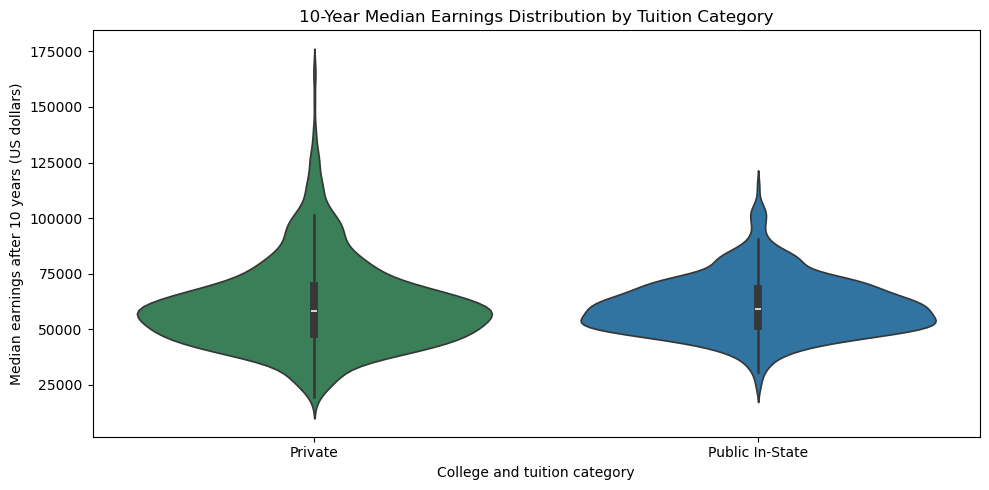

In [12]:
plt.figure(figsize=(10, 5))
sns.violinplot(
    data=analysis_df,
    x='category',
    y='earnings_10yr',
    order=category_order,
    hue='category',
    hue_order=category_order,
    palette=chart_colors,
    inner='box',
    legend=False
)
plt.title('10-Year Median Earnings Distribution by Tuition Category')
plt.xlabel('College and tuition category')
plt.ylabel('Median earnings after 10 years (US dollars)')
plt.tight_layout()
plt.show()


In [13]:
project_summary = analysis_df.groupby('category').agg(
    institutions=('earnings_10yr', 'count'),
    median_tuition=('tuition', 'median'),
    median_earnings_10yr=('earnings_10yr', 'median'),
)
project_summary['pearson_r_tuition_earnings'] = [
    analysis_df.loc[analysis_df['category'].eq(category), 'tuition'].corr(
        analysis_df.loc[analysis_df['category'].eq(category), 'earnings_10yr']
    )
    for category in project_summary.index
]
project_summary = project_summary.rename(index={'Public In-State': 'Public'})
display(project_summary.round(3))

,institutions,median_tuition,median_earnings_10yr,pearson_r_tuition_earnings
category,,,,
Private,1165,35760.0,58029.0,0.644
Public,566,10329.5,59271.5,0.523


## Findings and limitations

The filtered dataset contains 1,731 institutions: 566 public and 1,165 private. Private combines nonprofit and for-profit control codes. Median annual in-state tuition is about $10,330 for public institutions and $35,760 for private institutions, while median 10-year earnings are similar at about $59,272 and $58,029, respectively. Tuition and 10-year earnings have positive within-group Pearson correlations (about 0.523 for public institutions and 0.644 for private institutions). These are descriptive institution-level associations; they do not show that higher tuition causes higher earnings.

This sample is limited to predominantly bachelor's-degree institutions with usable reported values. Suppressed or missing observations are excluded, and earnings may reflect different student cohorts than the tuition figures. The comparison does not control for field of study, location, student preparation, selectivity, financial aid, inflation, or living costs. Public in-state tuition is a benchmark, not the price paid by every student.

The companion [`RESULTS.md`](RESULTS.md) and `analyze_college_scorecard.py` provide the complete interpretation and rerunnable figure generation.

## Final Notebook checks

This cell confirms that the cleaned output fields are present, the primary analysis includes Private and Public In-State, and the tuition box plot includes all three tuition categories. It is a structural check rather than an interpretation of the charts.


In [14]:
required_columns = [
    'unit_id', 'institution_name', 'tuition_in',
    'tuition_out', 'earnings_10yr', 'earnings_count', 'institution_type'
]
print('All required columns present:', set(required_columns).issubset(set(cleaned_df.columns)))
print('Primary comparison categories present:', set(category_order).issubset(set(analysis_df['category'])))
print('Tuition box-plot categories present:', set(tuition_order).issubset(set(tuition_df['category'])))
print('Rows in final cleaned table:', len(cleaned_df))
print('Notebook task check completed.')


All required columns present: True
Primary comparison categories present: True
Tuition box-plot categories present: True
Rows in final cleaned table: 1731
Notebook task check completed.
